# Northern Beaches Water Quality — Main Model + Generalisation (grouped CV by site)
ENGG2112 · AI for Good

**Goal:** predict the **enterococci count** (CFU/100 mL) at a swim site on a given day, with a **likely range**, and turn it into a safe / poor call (guideline: ≥ 41 CFU/100 mL = poor).

This notebook **consolidates** the earlier attempts (`Prediction-AI`, `prediction_count`, and `rainfall_regression_safe_to_swim`) into one model:
- **From the rainfall-regression notebook:** long rain windows, heaviest day, days since rain, Ridge model, cut-off tuned on validation.
- **From prediction_count:** previous-sample inputs, likely range (10th–90th percentile).
- **New:** upstream catchment rain, recent sunlight, simple baselines, an RF + XGBoost average, feature importance, optional site-type table.
- **Removed:** `site_rate` (a site's own past exceedance rate) because it can't exist for a site the model hasn't trained on (Part 2: generalisation to unseen sites); the lagoon keyword flag (replaced by the researched site-type table); days-until-safe (failed its back-test; Part 3 will redo it properly).

| Section | What happens |
|---|---|
| 0–1 | Imports and settings |
| 2 | **Data cleaning**: blanks, impossible values, duplicates, averaging repeats, sorting |
| 3–4 | Labels and quick checks |
| 5 | **Data merging**: rainfall, catchment rain and sunlight from SILO |
| 6 | Features (model inputs), incl. optional site types |
| 7 | **Data splitting** by date: train / validation / test, fill blanks |
| 8 | Baselines and models |
| 9 | Train, compare on validation, tune the cut-off, feature importance |
| 10 | Final test results, likely range, example output |
| **Part A** (7–10) | Known sites: date split, the "within-site" reference result |
| **Part B** (11) | **Unseen sites: grouped cross-validation by site** (8 groups: 6 train / 1 validation / 1 test, rotated) |
| 12 | Stricter check: unseen sites **and** future years |
| 13 | Do latitude/longitude help, or just let the model memorise sites? |
| 14 | Generalisation gap summary |
| 15 | Next steps |

## 0. Imports

### 0.1 Load libraries
**What it does:** Loads the toolkits: pandas (tables), matplotlib (plots), scikit-learn (Logistic Regression, Random Forest, metrics) and XGBoost. If XGBoost is missing, run `pip install xgboost` (and `pip install openpyxl` for the rainfall .xlsx files).

**Output:** Nothing. An error here means a library isn't installed.

In [1]:
import glob
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, r2_score, precision_score,
                             recall_score, f1_score)
from xgboost import XGBRegressor

## 1. Settings

### 1.1 Config
**What it does:** All the settings in one place. Change things here, not further down.
- `THRESHOLD`: poor = enterococci **≥** 41 CFU/100 mL. ⚠️ Check the comparator (≥ vs >) against the NHMRC/Beachwatch source and cite it.
- `RAIN_WINDOWS`: days of rain added up (long windows matter for lagoons, which drain slowly). `RAIN_EVENT_MM`: a day with at least this much rain counts as a "rain day" for *days since rain*.
- `CATCHMENT_POINTS`: inland SILO points (not nearest to any swim site) averaged into an **upstream catchment rain** signal.
- `SITE_TYPES_PATH`: the researched site-type table. If the file doesn't exist yet, site features are skipped automatically.
- `USE_LOCATION`: include latitude/longitude as inputs (to be tested in Part 2: they can let the model memorise sites).
- `VAL_START` / `TEST_START`: the dates that split train / validation / test.
- `N_GROUPS` / `N_REPEATS` / `CV_MODELS`: Part B grouped cross-validation settings (8 site groups, rotation repeated 3 times; Random Forest is left out by default because it is slow).
- `RANGE`: the likely range (10th to 90th percentile should contain ~80% of real values).

**Output:** Nothing.

In [2]:
DATA_PATH = 'Water quality-Data.csv'
RAIN_FILES = sorted(glob.glob('* (*, *).xlsx'))   # 13 SILO files, 2000-01-01 → 2026-10-07
SITE_TYPES_PATH = 'site_types.csv'                # optional: columns site, site_type, enclosed, outlet_nearby

SITES = 'all'
FOCUS_SITE = 'Narrabeen Lagoon (Birdwood Park)'
THRESHOLD = 41

RAIN_WINDOWS = [1, 2, 3, 5, 7, 14, 30]
RAIN_EVENT_MM = 2
DSR_CAP = 30                                      # days-since-rain is capped at this
CATCHMENT_POINTS = ['Beacon Hill', 'Duffys Forest', 'Ingleside', 'Terrey Hills']
USE_LOCATION = True

VAL_START = '2018-01-01'    # train:      before 2018
TEST_START = '2021-01-01'   # validation: 2018-2020   test: 2021 onwards
RANGE = (0.1, 0.9)
RANDOM_STATE = 42

# --- Part B: grouped cross-validation by site ---
N_GROUPS = 8                 # sites split into 8 groups: each round 6 train / 1 validation / 1 test
N_REPEATS = 3                # repeat the whole rotation with 3 different random groupings
CV_MODELS = ['XGBoost', 'Ridge']   # add 'RF + XGBoost average' if you don't mind a much longer run (RF is slow)
CUT_CANDS = np.arange(5, 61)       # cut-offs scanned when tuning on the validation group


## 2. Data cleaning
Takes the raw Beachwatch CSV and turns it into one clean row per site per sampling day. Each check is its own cell so you can see what it removed or changed.

### 2.1 Load the raw data
**What it does:** Reads the Beachwatch CSV exactly as downloaded. `raw` is kept untouched so we can always compare against it.

**Output:** Number of rows and columns, then the first 5 rows.

In [3]:
raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig')   # utf-8-sig strips the hidden BOM character on the first header
print('Raw data:', raw.shape[0], 'rows,', raw.shape[1], 'columns')
raw.head()

Raw data: 55507 rows, 9 columns


,Region,Council,Swim site,Date,Time,Enterococci (cfu/100mL),Water temperature (°C),Latitude,Longitude
0,Northern Sydney,Northern Beaches Council,Shelly Beach (Manly),21/9/2026,8:18:00,1.0,18.0,-33.800514,151.297668
1,Northern Sydney,Northern Beaches Council,Whale Beach,21/9/2026,9:27:00,0.0,18.0,-33.611207,151.332254
2,Northern Sydney,Northern Beaches Council,South Curl Curl Beach,21/9/2026,8:54:00,0.0,18.0,-33.773397,151.293337
3,Northern Sydney,Northern Beaches Council,Collaroy Beach,21/9/2026,9:49:00,0.0,19.0,-33.732619,151.302884
4,Northern Sydney,Northern Beaches Council,Avalon Beach,21/9/2026,9:14:00,0.0,18.0,-33.635658,151.332569


### 2.2 Rename columns, convert dates, keep useful columns
**What it does:** Gives columns short names, turns the date text (`21/9/2026`) into real dates, and keeps only the columns we use. Region, Council and Time are dropped (not used as features).

**Output:** Column names and their data types (`date` should be `datetime64`).

In [4]:
df = raw.rename(columns={
    'Swim site': 'site',
    'Enterococci (cfu/100mL)': 'entero',
    'Water temperature (°C)': 'water_temp',
})
df['date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df[['site', 'date', 'entero', 'water_temp', 'Latitude', 'Longitude']]
df.dtypes

site                     str
date          datetime64[us]
entero               float64
water_temp           float64
Latitude             float64
Longitude            float64
dtype: object

### 2.3 Select sites
**What it does:** Keeps only the sites listed in `SITES` (all of them by default).

**Output:** How many sites are in the file, and how many rows are kept.

In [5]:
print('Sites in file:', df['site'].nunique())
if SITES != 'all':
    df = df[df['site'].isin(SITES)]
df = df.copy()
print('Rows kept:', len(df), 'from', df['site'].nunique(), 'sites')

Sites in file: 42
Rows kept: 55507 from 42 sites


### 2.4 Blank records report
**What it does:** Counts the blank (missing) values in every column before we fix anything.

**Output:** A table of blank counts and % blank per column. Expect a few blank `entero` values and lots of blank `water_temp` (it wasn't recorded in early years).

In [6]:
pd.DataFrame({'blank records': df.isna().sum(),
              '% blank': (df.isna().mean() * 100).round(1)})

,blank records,% blank
site,0,0.0
date,0,0.0
entero,135,0.2
water_temp,23886,43.0
Latitude,0,0.0
Longitude,0,0.0


### 2.5 Remove rows with no enterococci result
**What it does:** A row without an enterococci result has no answer to learn from, so it's removed. Blank `water_temp` rows are **kept**: those get filled in Section 7.2.

**Output:** Rows before and after, and how many were removed.

In [7]:
before = len(df)
df = df.dropna(subset=['entero'])
print(f'Before: {before} | After: {len(df)} | Removed: {before - len(df)} rows with blank enterococci')

Before: 55507 | After: 55372 | Removed: 135 rows with blank enterococci


### 2.6 Fix impossible water temperatures
**What it does:** Some water temperatures are entry errors (e.g. 245 or 1616 °C, probably missing decimal points). Anything outside 5–35 °C is set to blank rather than guessed.

**Output:** How many values were blanked, and the remaining min/max (should be within 5–35).

In [8]:
bad = df['water_temp'].notna() & ~df['water_temp'].between(5, 35)
print('Impossible values found:', bad.sum(), '→', sorted(df.loc[bad, 'water_temp'].unique().tolist()))
df.loc[bad, 'water_temp'] = np.nan
print('Water temp range now:', df['water_temp'].min(), '→', df['water_temp'].max(), '°C')

Impossible values found: 12 → [2.0, 129.0, 156.0, 200.0, 217.0, 222.0, 227.0, 234.0, 242.0, 245.0, 1536.0, 1616.0]
Water temp range now: 9.0 → 29.0 °C


### 2.7 Duplicates and averaging repeat samples
**What it does:** Two kinds of duplicates:
1. **Exact copies** (same row entered twice) are deleted. Because Time was dropped in 2.2, same-day re-tests with identical results also count as copies here.
2. **Repeat samples** (same site and day, different results, e.g. a re-test in the afternoon) are **averaged** into one row, so each site has at most one sample per day.

**Output:** Number of exact copies removed, a table of the repeat samples, and the row count after averaging.

In [9]:
before = len(df)
df = df.drop_duplicates()
print('Exact duplicate rows removed:', before - len(df))

repeats = df.duplicated(['site', 'date'], keep=False)
print('Repeat samples (same site + day, different results):', repeats.sum())
display(df[repeats].sort_values(['site', 'date']))

df = (df.groupby(['site', 'date'], as_index=False)
        .agg(entero=('entero', 'mean'), water_temp=('water_temp', 'mean'),
             Latitude=('Latitude', 'first'), Longitude=('Longitude', 'first')))
print('Rows after averaging repeats:', len(df))

Exact duplicate rows removed: 9
Repeat samples (same site + day, different results): 4


,site,date,entero,water_temp,Latitude,Longitude
55303,Clontarf Pool,2000-02-01,460.0,NaN,-33.805790,151.251720
55304,Clontarf Pool,2000-02-01,16.0,NaN,-33.805790,151.251720
11426,South Scotland Island,2020-10-26,36.0,19.0,-33.644454,151.291354
11427,South Scotland Island,2020-10-26,36.0,18.0,-33.644454,151.291354


Rows after averaging repeats: 55361


### 2.8 Sort by site and date
**What it does:** Puts each site's samples in date order. Needed so 'previous sample' features in Section 6 really are the previous sample.

**Output:** The first 5 rows (one site, earliest dates first) and the final cleaned row count.

In [10]:
df = df.sort_values(['site', 'date']).reset_index(drop=True)
print('Clean data:', len(df), 'rows,', df['site'].nunique(), 'sites,',
      df['date'].min().date(), '→', df['date'].max().date())
df.head()

Clean data: 55361 rows, 42 sites, 2000-01-02 → 2026-09-21


,site,date,entero,water_temp,Latitude,Longitude
0,Avalon Beach,2000-01-04,0.0,NaN,-33.635658,151.332569
1,Avalon Beach,2000-01-11,6.0,NaN,-33.635658,151.332569
2,Avalon Beach,2000-01-16,12.0,NaN,-33.635658,151.332569
3,Avalon Beach,2000-01-22,90.0,NaN,-33.635658,151.332569
4,Avalon Beach,2000-01-28,6.0,NaN,-33.635658,151.332569


## 3. Labels

### 3.1 Create the poor/safe label
**What it does:** Adds `poor`: 1 if enterococci ≥ `THRESHOLD`, otherwise 0. Not what the models predict here, but used later to score the predicted counts as poor/safe.

**Output:** Samples and exceedance rate per site, highest first (lagoons/baths should be at the top).

In [11]:
df['poor'] = (df['entero'] >= THRESHOLD).astype(int)

(df.groupby('site')['poor'].agg(['count', 'mean'])
   .rename(columns={'count': 'samples', 'mean': 'exceed_rate'})
   .sort_values('exceed_rate', ascending=False).round(3))

,samples,exceed_rate
site,,
Bilarong Reserve,722,0.324
Narrabeen Lagoon (Birdwood Park),1230,0.287
Davidson Reserve,1223,0.246
Sangrado Baths,593,0.241
Bayview Baths,1213,0.228
Salt Pan Cove Baths,594,0.178
Gurney Crescent Baths,1224,0.164
Queenscliff Beach,1576,0.146
Winji Jimmi Bay,594,0.136


### 3.2 Prediction target: log of the count
**What it does:** Enterococci counts are extremely skewed: most are 0–10, a few are in the thousands. Predicting raw counts would let a handful of huge values dominate, so the models predict `log_entero = log(1 + count)` instead. Predictions are converted back to counts with `exp(x) - 1`.

**Output:** Two histograms: raw counts (squashed against zero with a long tail) and log counts (much more even).

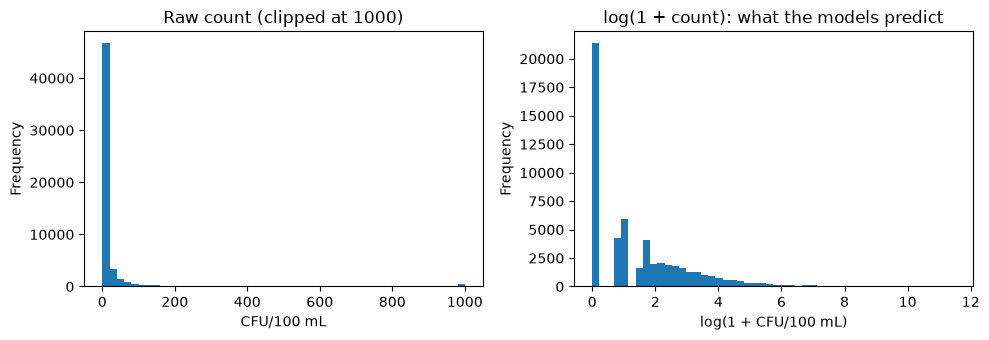

In [12]:
df['log_entero'] = np.log1p(df['entero'])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df['entero'].clip(upper=1000).plot(kind='hist', bins=50, ax=axes[0], title='Raw count (clipped at 1000)')
df['log_entero'].plot(kind='hist', bins=50, ax=axes[1], title='log(1 + count): what the models predict')
axes[0].set_xlabel('CFU/100 mL'); axes[1].set_xlabel('log(1 + CFU/100 mL)')
plt.tight_layout()
plt.show()

### 3.3 Poor vs safe balance
**What it does:** Bar chart of safe vs poor samples.

**Output:** A bar chart. Poor is the minority (~9% overall), so we check poor/safe recall and F1 later, not just count error.

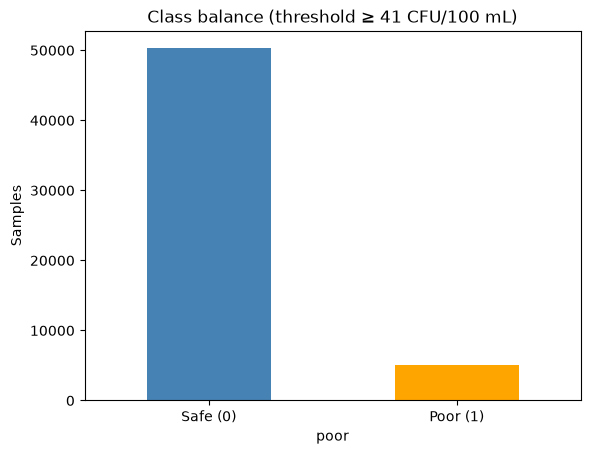

In [13]:
df['poor'].value_counts().sort_index().plot(kind='bar', color=['steelblue', 'orange'])
plt.xticks([0, 1], ['Safe (0)', 'Poor (1)'], rotation=0)
plt.ylabel('Samples')
plt.title(f'Class balance (threshold ≥ {THRESHOLD} CFU/100 mL)')
plt.show()

## 4. Quick checks

### 4.1 Sampling interval
**What it does:** Works out how many days apart each site's samples are.

**Output:** Summary stats of the gap in days (median should be ~6).

In [14]:
df.groupby('site')['date'].diff().dt.days.describe()

count    55319.000000
mean         6.878667
std          4.631884
min          1.000000
25%          6.000000
50%          6.000000
75%          7.000000
max        124.000000
Name: date, dtype: float64

### 4.2 Exceedance rate by year
**What it does:** Plots the share of poor samples each year, with the validation and test periods marked. Big differences between periods would make the models' job harder (drift).

**Output:** A line chart with two dashed lines (validation start, test start).

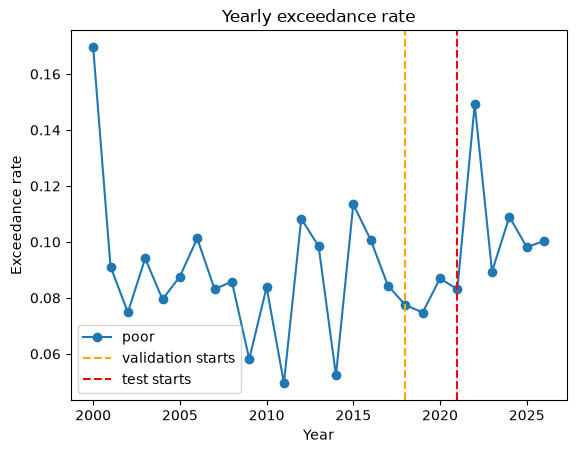

In [15]:
df.groupby(df['date'].dt.year)['poor'].mean().plot(marker='o')
plt.axvline(pd.Timestamp(VAL_START).year, color='orange', ls='--', label='validation starts')
plt.axvline(pd.Timestamp(TEST_START).year, color='red', ls='--', label='test starts')
plt.ylabel('Exceedance rate'); plt.xlabel('Year'); plt.legend()
plt.title('Yearly exceedance rate')
plt.show()

## 5. Data merging: rainfall, catchment rain and sunlight (SILO)
Daily weather from **SILO** (built from BOM observations, gap-free). 13 files: 11 grid points (interpolated, 0.05° grid) and 2 real stations (Mona Vale Golf Club 66141, Palm Beach Sunrise Rd 66128).

⚠️ Cite SILO as the data source (CC BY 4.0 licence requires it). ⚠️ To verify: SILO daily rain for date D should be the 24h to **9am on D** (BOM convention). Confirm in SILO's documentation and cite it.

### 5.1 Load the SILO files
**What it does:** Reads each .xlsx: coordinates from the notes at the top, then the daily table. Keeps daily **rainfall** (mm) and **solar radiation** (MJ/m², sunlight kills bacteria).

**Output:** How many points loaded (13) and each point's coordinates and date range.

In [16]:
def load_silo(path):
    """Read one SILO xlsx -> (lat, lon, DataFrame of daily Rain and Radn indexed by date)."""
    raw_xl = pd.read_excel(path, header=None)

    # Coordinates are in the notes block, e.g. 'Lat, Long: -33.80 151.25' or 'Lat: -33.6795 Long: 151.3076'
    notes = ' '.join(str(v) for v in raw_xl[0].head(40))
    lat, lon = map(float, re.search(r'Lat(?:, Long)?:\s*(-?\d+\.\d+)\s*(?:Long:)?\s*(-?\d+\.\d+)', notes).groups())

    # Table starts at the 'Date' header row, then a units row, then data
    h = raw_xl.index[raw_xl[0].astype(str).str.strip() == 'Date'][0]
    d = raw_xl.iloc[h + 2:].copy()
    d.columns = raw_xl.iloc[h].astype(str).str.strip()
    d = d[pd.to_numeric(d['Date'], errors='coerce').notna()]
    d['date'] = pd.to_datetime(d['Date'].astype(int).astype(str), format='%Y%m%d')
    return lat, lon, d.set_index('date')[['Rain', 'Radn']].astype(float)

points = {}
for f in RAIN_FILES:
    lat, lon, weather = load_silo(f)
    points[f.split(' (')[0]] = {'lat': lat, 'lon': lon, 'weather': weather}

print(len(points), 'SILO points loaded')
pd.DataFrame({name: {'lat': p['lat'], 'lon': p['lon'], 'from': p['weather'].index.min().date(),
                     'to': p['weather'].index.max().date(), 'blank days': int(p['weather'].isna().sum().sum())}
              for name, p in points.items()}).T

13 SILO points loaded


,lat,lon,from,to,blank days
Balgowlah,-33.8,151.25,2000-01-01,2026-10-07,0
Beacon Hill,-33.75,151.25,2000-01-01,2026-10-07,0
Belrose,-33.75,151.2,2000-01-01,2026-10-07,0
Dee Why,-33.75,151.3,2000-01-01,2026-10-07,0
Duffys Forest,-33.65,151.2,2000-01-01,2026-10-07,0
Ingleside,-33.7,151.25,2000-01-01,2026-10-07,0
Manly,-33.8,151.3,2000-01-01,2026-10-07,0
Mona Vale,-33.6795,151.3076,2000-01-01,2026-10-07,0
Newport,-33.65,151.3,2000-01-01,2026-10-07,0
North Narrabeen,-33.7,151.3,2000-01-01,2026-10-07,0


### 5.2 Match each swim site to its nearest point
**What it does:** Straight-line distance from each swim site to every SILO point; the closest one supplies that site's local rain and sunlight. Several sites can share one point.

**Output:** A table: site → point and distance (all within ~3.5 km). The catchment points should not appear here.

In [17]:
def nearest_point(lat, lon):
    dist = {name: 111.2 * np.hypot(p['lat'] - lat, (p['lon'] - lon) * np.cos(np.radians(lat)))
            for name, p in points.items()}
    best = min(dist, key=dist.get)
    return best, dist[best]

site_xy = df.groupby('site')[['Latitude', 'Longitude']].first()
site_map = pd.DataFrame(
    [(site, *nearest_point(r['Latitude'], r['Longitude'])) for site, r in site_xy.iterrows()],
    columns=['site', 'rain_point', 'dist_km']).set_index('site')
print('Catchment points used by a swim site (should be none):',
      sorted(set(site_map['rain_point']) & set(CATCHMENT_POINTS)))
site_map.sort_values('rain_point').round(1)

Catchment points used by a swim site (should be none): []


,rain_point,dist_km
site,,
Fairlight Beach,Balgowlah,2.3
Sangrado Baths,Balgowlah,1.1
Forty Baskets Pool,Balgowlah,1.9
Gurney Crescent Baths,Balgowlah,1.5
Clontarf Pool,Balgowlah,0.7
Davidson Reserve,Belrose,2.0
North Curl Curl Beach,Dee Why,2.0
Dee Why Beach,Dee Why,0.4
Collaroy Beach,Dee Why,2.0


### 5.3 Local weather features
**What it does:** One function, `weather_features()`, turns a point's daily weather into model inputs, so the same code can be reused later (e.g. for simulations in Part 3):
- `rain_1d … rain_30d`: rain added up over the last 1, 2, 3, 5, 7, 14, 30 days (ending 9am on the sample day).
- `max_rain_7d`: heaviest single day in the last 7 (intensity: 30 mm in one day washes in more than 30 mm over a week).
- `days_since_rain`: days since the last day with ≥ `RAIN_EVENT_MM` (capped at 30).
- `sun_3d`: average solar radiation over the **3 days before** the sample day (the sample day itself isn't used: its afternoon sunshine hasn't happened yet at a morning sample).

**Output:** The first rows for one point. Long windows are blank for the first month of 2000 (not enough history).

In [18]:
RAIN_COLS = [f'rain_{w}d' for w in RAIN_WINDOWS] + ['max_rain_7d', 'days_since_rain']

def weather_features(weather):
    """Daily Rain/Radn (DataFrame indexed by date) -> DataFrame of weather features, one row per day."""
    w = weather.asfreq('D')                       # one row per day so rolling windows are in days
    r = w['Rain']
    out = pd.DataFrame(index=w.index)
    for n in RAIN_WINDOWS:
        out[f'rain_{n}d'] = r.rolling(n).sum()
    out['max_rain_7d'] = r.rolling(7).max()
    pos = np.arange(len(r))
    last_rain = pd.Series(np.where(r.values >= RAIN_EVENT_MM, pos, np.nan), index=r.index).ffill()
    out['days_since_rain'] = (pos - last_rain).fillna(DSR_CAP).clip(upper=DSR_CAP)
    out['sun_3d'] = w['Radn'].shift(1).rolling(3).mean()
    return out

frames = []
for name, p in points.items():
    f = weather_features(p['weather'])
    f['rain_point'] = name
    frames.append(f)
weather_feats = pd.concat(frames).rename_axis('date').reset_index()
weather_feats[weather_feats['rain_point'] == list(points)[0]].head(8)

,date,rain_1d,rain_2d,rain_3d,rain_5d,rain_7d,rain_14d,rain_30d,max_rain_7d,days_since_rain,sun_3d,rain_point
0,2000-01-01,0.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,NaN,Balgowlah
1,2000-01-02,10.0,10.4,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,Balgowlah
2,2000-01-03,3.4,13.4,13.8,NaN,NaN,NaN,NaN,NaN,0.0,NaN,Balgowlah
3,2000-01-04,0.1,3.5,13.5,NaN,NaN,NaN,NaN,NaN,1.0,20.633333,Balgowlah
4,2000-01-05,0.0,0.1,3.5,13.9,NaN,NaN,NaN,NaN,2.0,21.866667,Balgowlah
5,2000-01-06,0.0,0.0,0.1,13.5,NaN,NaN,NaN,NaN,3.0,28.066667,Balgowlah
6,2000-01-07,0.0,0.0,0.0,3.5,13.9,NaN,NaN,10.0,4.0,27.266667,Balgowlah
7,2000-01-08,2.3,2.3,2.3,2.4,15.8,NaN,NaN,10.0,0.0,24.200000,Balgowlah


### 5.4 Upstream catchment rain
**What it does:** Averages daily rain over the inland `CATCHMENT_POINTS` (the hills that drain towards the lagoons and creeks), then adds it up over 3 and 7 days. Same values for every site on a given day.

**Output:** The first rows of the catchment table.

In [19]:
catch_daily = pd.concat([points[n]['weather']['Rain'] for n in CATCHMENT_POINTS], axis=1).mean(axis=1).asfreq('D')
catch_feats = pd.DataFrame({'catch_rain_3d': catch_daily.rolling(3).sum(),
                            'catch_rain_7d': catch_daily.rolling(7).sum()}).rename_axis('date').reset_index()
catch_feats.head(8)

,date,catch_rain_3d,catch_rain_7d
0,2000-01-01,NaN,NaN
1,2000-01-02,NaN,NaN
2,2000-01-03,16.325,NaN
3,2000-01-04,15.750,NaN
4,2000-01-05,2.175,NaN
5,2000-01-06,0.000,NaN
6,2000-01-07,0.000,16.325
7,2000-01-08,7.150,22.900


### 5.5 Merge weather into the water quality data
**What it does:** Joins local weather on (nearest point, date) and catchment rain on date. Samples without full rain history (only the first month of 2000) are dropped.

**Output:** Row count before/after the merge (must be the same) and how many early rows were dropped.

In [20]:
WEATHER_COLS = RAIN_COLS + ['sun_3d', 'catch_rain_3d', 'catch_rain_7d']

before = len(df)
df = df.drop(columns=WEATHER_COLS + ['rain_point'], errors='ignore')   # safe to re-run
df['rain_point'] = df['site'].map(site_map['rain_point'])
df = df.merge(weather_feats, on=['rain_point', 'date'], how='left')
df = df.merge(catch_feats, on='date', how='left')
print(f'Rows before merge: {before} | after merge: {len(df)}')

n = len(df)
df = df.dropna(subset=WEATHER_COLS).reset_index(drop=True)
print(f'Dropped {n - len(df)} rows with incomplete weather history (start of 2000)')

Rows before merge: 55361 | after merge: 55361
Dropped 184 rows with incomplete weather history (start of 2000)


### 5.6 Check: does rain relate to poor water?
**What it does:** Exceedance rate by rain in the previous 72h.

**Output:** A table. Exceedance should climb steeply with rainfall.

In [21]:
bands = pd.cut(df['rain_3d'], [-0.1, 0, 5, 20, 50, np.inf], labels=['0', '0-5', '5-20', '20-50', '50+'])
(df.groupby(bands, observed=True)['poor'].agg(['count', 'mean'])
   .rename(columns={'count': 'samples', 'mean': 'exceed_rate'}).round(3))

,samples,exceed_rate
rain_3d,,
0,15495,0.029
0-5,20179,0.046
5-20,11617,0.117
20-50,5289,0.228
50+,2597,0.438


## 6. Features (model inputs)
Only information known **before** the sample is taken, and nothing that only exists for sites the model has trained on.

### 6.1 Sample history and season
**What it does:** Looks back at the **previous sample at the same site**: its result (log), whether it was poor, how many days ago, and its water temperature (same-day water temp is measured *at* sampling, so it isn't allowed). Month as sin/cos so Dec and Jan count as close. Allowed under the current Part 2 scenario (held-out sites are monitored, just not in training).

**Output:** Nothing printed (adds columns).

In [22]:
g = df.groupby('site')
df['prev_entero_log'] = np.log1p(g['entero'].shift(1))
df['prev_poor'] = g['poor'].shift(1)
df['days_since_prev'] = g['date'].diff().dt.days
df['prev_water_temp'] = g['water_temp'].shift(1)
df['month_sin'] = np.sin(2 * np.pi * df['date'].dt.month / 12)
df['month_cos'] = np.cos(2 * np.pi * df['date'].dt.month / 12)

### 6.2 Site types (optional, from the researched table)
**What it does:** If `site_types.csv` exists, adds the researched site characteristics. Expected columns (site names exactly as in the data):
- `site`, `site_type` (e.g. lagoon / ocean beach / ocean pool / estuary bay / estuary baths), `enclosed` (Yes / Partly / No), `outlet_nearby` (Yes / No). The headers from the shared template ('Site type', 'Enclosed?', 'Lagoon or creek outlet within ~500 m?') also work.

Sites missing from the table get blanks, which 7.2 fills with the training median.

`site_type` becomes one 0/1 column per type; `enclosed` → 1 / 0.5 / 0; `outlet_nearby` → 1 / 0. If the file isn't there yet, this step is skipped and everything else still runs.

**Output:** Either 'not found yet' or the site features added, plus any sites missing from the table.

In [23]:
SITE_FEATURES = []
df = df.drop(columns=[c for c in df if c.startswith('type_')] + ['enclosed', 'outlet_nearby'], errors='ignore')

if os.path.exists(SITE_TYPES_PATH):
    st = pd.read_csv(SITE_TYPES_PATH)
    # accept headers like 'Site type', 'Enclosed?' or 'Lagoon or creek outlet within ~500 m?'
    st.columns = st.columns.str.strip().str.lower().str.replace(r'[^a-z0-9]+', '_', regex=True).str.strip('_')
    st = st.rename(columns={c: 'outlet_nearby' for c in st.columns if c.startswith('lagoon_or_creek')})
    clean = lambda s: s.astype(str).str.strip().str.lower()
    first_word = lambda s: clean(s).str.extract(r'^([a-z]+)', expand=False)   # 'Yes – enclosed water body' -> 'yes'
    st['site'] = st['site'].astype(str).str.strip()
    st['enclosed'] = first_word(st['enclosed']).map({'yes': 1, 'partly': 0.5, 'semi': 0.5, 'no': 0})
    st['outlet_nearby'] = first_word(st['outlet_nearby']).map({'yes': 1, 'possibly': 0.5, 'no': 0})   # 'Unsure' -> blank
    types = pd.get_dummies(clean(st['site_type']), prefix='type', dtype=int)
    st = pd.concat([st[['site', 'enclosed', 'outlet_nearby']], types], axis=1)

    missing = sorted(set(df['site']) - set(st['site']))
    print('Sites missing from the table:', missing or 'none')
    df = df.merge(st, on='site', how='left')
    SITE_FEATURES = ['enclosed', 'outlet_nearby'] + list(types.columns)
    print('Site features added:', SITE_FEATURES)
else:
    print(f'{SITE_TYPES_PATH} not found yet: site features skipped')

Sites missing from the table: none
Site features added: ['enclosed', 'outlet_nearby', 'type_estuarine beach', 'type_harbour beach', 'type_lagoon', 'type_netted baths / enclosure', 'type_ocean beach', 'type_tidal pool']


### 6.3 Final feature list
**What it does:** Lists every input the models use and removes each site's very first sample (no previous sample).

**Output:** The feature list and summary stats. `count` below the row total = blanks still to fill (7.2).

In [24]:
FEATURES = (
    ['prev_entero_log', 'prev_poor', 'days_since_prev', 'prev_water_temp']   # sample history
    + RAIN_COLS + ['catch_rain_3d', 'catch_rain_7d', 'sun_3d']               # weather
    + ['month_sin', 'month_cos']                                             # season
    + (['Latitude', 'Longitude'] if USE_LOCATION else [])                    # location
    + SITE_FEATURES                                                          # site types (if available)
)
TARGET = 'log_entero'

df = df.dropna(subset=['prev_poor']).reset_index(drop=True)
print(len(FEATURES), 'features | rows:', len(df))
df[FEATURES].describe().round(2)

28 features | rows: 55135


,prev_entero_log,prev_poor,days_since_prev,prev_water_temp,rain_1d,rain_2d,rain_3d,rain_5d,rain_7d,rain_14d,...,Latitude,Longitude,enclosed,outlet_nearby,type_estuarine beach,type_harbour beach,type_lagoon,type_netted baths / enclosure,type_ocean beach,type_tidal pool
count,55135.00,55135.00,55135.00,31425.00,55135.00,55135.00,55135.00,55135.00,55135.00,55135.00,...,55135.00,55135.00,55135.00,42495.00,55135.00,55135.00,55135.00,55135.0,55135.00,55135.00
mean,1.41,0.09,6.88,19.80,3.07,6.67,9.85,16.56,22.89,46.21,...,-33.71,151.30,0.41,0.32,0.19,0.07,0.04,0.1,0.57,0.04
std,1.59,0.29,4.64,2.85,9.17,16.35,21.12,28.87,34.94,53.04,...,0.07,0.03,0.38,0.45,0.39,0.25,0.18,0.3,0.50,0.21
min,0.00,0.00,1.00,9.00,0.00,0.00,0.00,0.00,0.00,0.00,...,-33.81,151.20,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
25%,0.00,0.00,6.00,18.00,0.00,0.00,0.00,0.50,2.00,11.00,...,-33.79,151.29,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
50%,1.10,0.00,6.00,20.00,0.00,0.40,1.50,5.40,10.10,28.90,...,-33.70,151.30,0.50,0.00,0.00,0.00,0.00,0.0,1.00,0.00
75%,2.30,0.00,7.00,22.00,1.50,5.50,10.00,20.10,28.40,62.45,...,-33.64,151.31,0.50,1.00,0.00,0.00,0.00,0.0,1.00,0.00
max,11.49,1.00,124.00,29.00,171.20,199.40,299.30,389.20,417.50,692.90,...,-33.59,151.33,1.00,1.00,1.00,1.00,1.00,1.0,1.00,1.00


# Part A: known sites (date split)
The reference result: the model is tested on **future years at sites it has trained on**. Part B then tests sites it has **never seen**.

## 7. Data splitting: train / validation / test by date
Split **by date** so the models are always judged on a "future" they haven't seen.
- **Train (2000–2017):** the models learn from this.
- **Validation (2018–2020):** compare models, tune the cut-off.
- **Test (2021+):** touched once at the end.

(Part 2 will add a second, **site-based** split: train on 80% of sites, test on the other 20%, rotated 5 times.)

### 7.1 Sort by date and split
**What it does:** Sorts all rows by date, then cuts at `VAL_START` and `TEST_START`.

**Output:** Rows, sites, date range and poor rate for each split.

In [25]:
df = df.sort_values('date').reset_index(drop=True)
train = df[df['date'] < VAL_START].copy()
val = df[(df['date'] >= VAL_START) & (df['date'] < TEST_START)].copy()
test = df[df['date'] >= TEST_START].copy()
splits = {'train': train, 'validation': val, 'test': test}

pd.DataFrame({name: {'rows': len(d), 'sites': d['site'].nunique(),
                     'from': d['date'].min().date(), 'to': d['date'].max().date(),
                     'poor rate': round(d['poor'].mean(), 3)}
              for name, d in splits.items()}).T

,rows,sites,from,to,poor rate
train,38545,42,2000-02-04,2017-12-29,0.09
validation,5596,39,2018-01-03,2020-12-17,0.079
test,10994,39,2021-01-04,2026-09-21,0.105


### 7.2 Fill remaining blanks with the training median
**What it does:** Remaining blanks (mostly `prev_water_temp`) are filled with each feature's median from the **training set only**, the same values for all three splits.

**Output:** Blank counts before filling, and a check that 0 remain.

In [26]:
print('Blank values before filling:')
display(pd.DataFrame({name: d[FEATURES].isna().sum() for name, d in splits.items()}).query('train + validation + test > 0'))

train_medians = train[FEATURES].median()
for d in splits.values():
    d[FEATURES] = d[FEATURES].fillna(train_medians)
print('Blank values remaining:', sum(d[FEATURES].isna().sum().sum() for d in splits.values()))

Blank values before filling:


,train,validation,test
prev_water_temp,23352,13,345
outlet_nearby,9156,1175,2309


Blank values remaining: 0


### 7.3 Separate inputs (X) from answers (y)
**What it does:** `X` = the feature columns, `y` = `log_entero` (log of the count).

**Output:** The shape of each X.

In [27]:
X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print('X_train', X_train.shape, '| X_val', X_val.shape, '| X_test', X_test.shape)

X_train (38545, 28) | X_val (5596, 28) | X_test (10994, 28)


## 8. Baselines and models

### 8.1 Scoring function
**What it does:** Every model and baseline is scored the same way:
- **MAE (log):** average gap between predicted and real log count. Lower is better.
- **Typical error ×:** roughly how many times too high or too low a typical prediction is (×2 = e.g. predicting 20 when the truth was 10 or 40). Based on the median error, on the log(1 + count) scale, so approximate.
- **R² (log):** share of the variation explained (1 = perfect, 0 = no better than guessing the average).
- **Recall / precision / F1 (poor):** predicted count ≥ `cutoff` treated as poor, compared with the real lab result.

**Output:** Nothing.

In [28]:
def score(y_true_log, y_pred_log, cutoff=THRESHOLD):
    true_poor = np.expm1(y_true_log) >= THRESHOLD
    pred_poor = np.expm1(y_pred_log) >= cutoff
    abs_err = np.abs(np.asarray(y_true_log) - np.asarray(y_pred_log))
    return {'MAE (log)': abs_err.mean(),
            'typical error ×': np.exp(np.median(abs_err)),
            'R² (log)': r2_score(y_true_log, y_pred_log),
            'recall (poor)': recall_score(true_poor, pred_poor, zero_division=0),
            'precision (poor)': precision_score(true_poor, pred_poor, zero_division=0),
            'F1 (poor)': f1_score(true_poor, pred_poor, zero_division=0)}

### 8.2 Baselines
**What it does:** Two "no machine learning" predictions, so the models' results mean something:
- **Previous sample:** predict the same count as the last sample at that site.
- **Training median:** predict the same typical count for everyone.

A model is only worth it if it clearly beats these.

**Output:** Nothing (baselines are scored alongside the models in 9.1 and 10.2).

In [29]:
baselines = {
    'Baseline: previous sample': lambda X: X['prev_entero_log'].values,
    'Baseline: training median': lambda X: np.full(len(X), y_train.median()),
}

### 8.3 Define the models
**What it does:** - **Ridge:** linear model (one weight per input), with a small penalty that stops weights going extreme.
- **Random Forest:** 300 trees, prediction = average.
- **XGBoost:** trees built one after another, each fixing the last one's mistakes.
- **RF + XGBoost average:** averages the two tree models' predictions. Averaging different models often cancels some of their errors.

**Output:** Nothing.

In [30]:
def make_rf():
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)

def make_xgb(**kw):
    return XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8,
                        colsample_bytree=0.8, random_state=RANDOM_STATE, **kw)

models = {
    'Ridge': Pipeline([('scale', StandardScaler()), ('reg', Ridge(alpha=1.0))]),
    'Random Forest': make_rf(),
    'XGBoost': make_xgb(),
    'RF + XGBoost average': VotingRegressor([('rf', make_rf()), ('xgb', make_xgb())]),
}

## 9. Train and compare on validation

### 9.1 Train on the training set, score on validation
**What it does:** Fits each model on train and predicts the validation years. Training R² vs validation R² shows overfitting (a big gap = memorising). Baselines are included for reference.

**Output:** A table: training R², then validation scores at the official 41 cut-off.

In [31]:
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    row = {'model': name, 'train R² (log)': r2_score(y_train, model.predict(X_train))}
    row.update({f'val {k}': v for k, v in score(y_val, model.predict(X_val)).items()})
    rows.append(row)
for name, predict in baselines.items():
    rows.append({'model': name, **{f'val {k}': v for k, v in score(y_val, predict(X_val)).items()}})
val_results = pd.DataFrame(rows).set_index('model').round(3)
val_results

,train R² (log),val MAE (log),val typical error ×,val R² (log),val recall (poor),val precision (poor),val F1 (poor)
model,,,,,,,
Ridge,0.346,0.975,2.123,0.071,0.241,0.718,0.361
Random Forest,0.767,0.898,2.061,0.366,0.306,0.716,0.429
XGBoost,0.517,0.874,2.010,0.377,0.297,0.721,0.421
RF + XGBoost average,0.665,0.881,2.020,0.381,0.300,0.704,0.420
Baseline: previous sample,NaN,1.311,3.000,-0.548,0.140,0.139,0.139
Baseline: training median,NaN,1.140,3.000,-0.027,0.000,0.000,0.000


### 9.2 Pick the best model
**What it does:** Lowest validation MAE among the models (not the baselines), decided **before** looking at the test set.

**Output:** The chosen model.

In [32]:
best = val_results.loc[list(models), 'val MAE (log)'].idxmin()
print('Best on validation:', best)

Best on validation: XGBoost


### 9.3 Tune the poor cut-off on validation
**What it does:** Regression pulls predictions towards the average, so it under-predicts spikes and a cut-off of exactly 41 misses many poor days. For each model, this scans cut-offs from 5 to 60 CFU/100 mL on the **validation** set and keeps the one with the best F1. (To favour catching poor days over avoiding false alarms, change `f1_score` to e.g. `fbeta_score(..., beta=2)`.)

**Output:** The tuned cut-off per model, and a plot of validation F1 vs cut-off for the best model.

Tuned cut-offs (CFU/100 mL): {'Ridge': 11.0, 'Random Forest': 19.0, 'XGBoost': 16.0, 'RF + XGBoost average': 17.0}


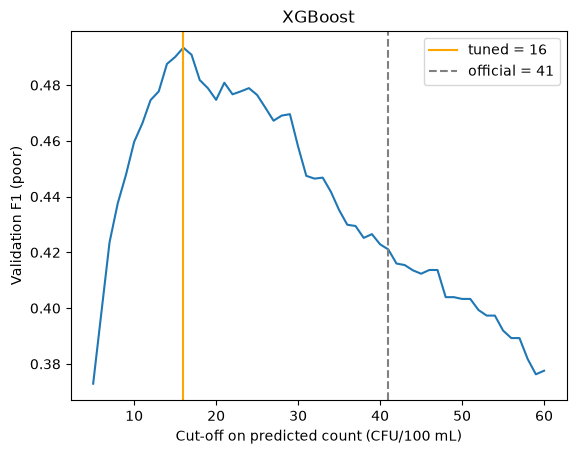

In [33]:
cands = np.arange(5, 61)
true_poor_val = np.expm1(y_val) >= THRESHOLD
CUTOFFS, curves = {}, {}
for name, model in models.items():
    pred_cfu = np.expm1(model.predict(X_val))
    curves[name] = [f1_score(true_poor_val, pred_cfu >= c) for c in cands]
    CUTOFFS[name] = float(cands[int(np.argmax(curves[name]))])
print('Tuned cut-offs (CFU/100 mL):', CUTOFFS)

plt.plot(cands, curves[best])
plt.axvline(CUTOFFS[best], color='orange', label=f'tuned = {CUTOFFS[best]:.0f}')
plt.axvline(THRESHOLD, color='grey', ls='--', label=f'official = {THRESHOLD}')
plt.xlabel('Cut-off on predicted count (CFU/100 mL)'); plt.ylabel('Validation F1 (poor)')
plt.title(best); plt.legend(); plt.show()

### 9.4 Feature importance
**What it does:** For the best model, shuffles one input at a time on the validation set and measures how much worse the predictions get (permutation importance). Big drop = the model relies on that input. Near zero = it adds little.

**Output:** A bar chart of the inputs, most important at the top.

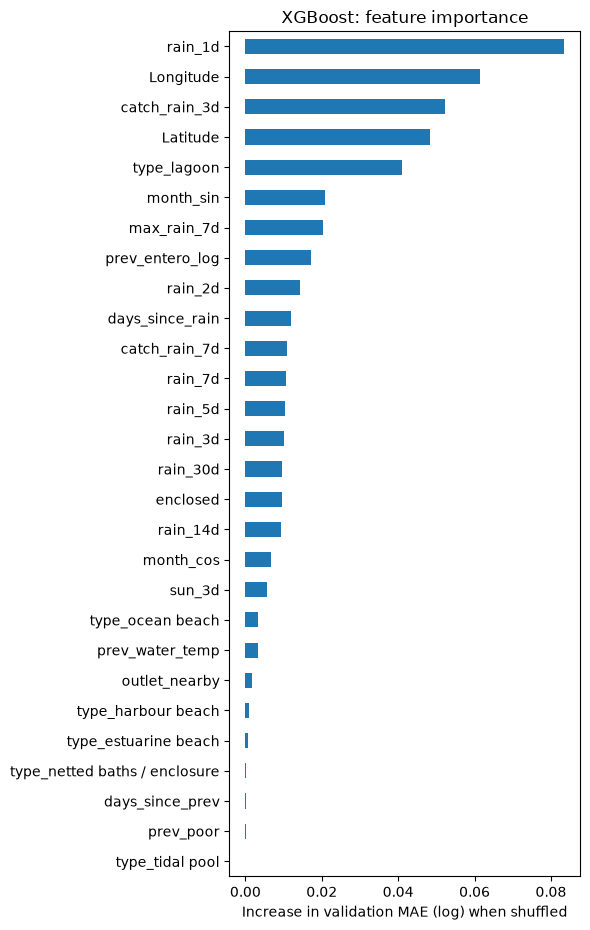

In [34]:
imp = permutation_importance(models[best], X_val, y_val, scoring='neg_mean_absolute_error',
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
imp.plot(kind='barh', figsize=(6, 0.3 * len(FEATURES) + 1))
plt.xlabel('Increase in validation MAE (log) when shuffled'); plt.title(f'{best}: feature importance')
plt.tight_layout(); plt.show()

## 10. Final results on the test set (2021+)

### 10.1 Retrain on train + validation
**What it does:** All choices are made, so each model is retrained on 2000–2020 to learn from the most recent years too.

**Output:** Nothing printed.

In [35]:
X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])
for model in models.values():
    model.fit(X_trval, y_trval)

### 10.2 Test-set scores
**What it does:** Each model and baseline predicts the 2021+ samples. Poor/safe scores use each model's **tuned** cut-off (baselines use 41).

**Output:** A table of count error and poor/safe scores.

In [36]:
rows = {name: {'cut-off': CUTOFFS[name], **score(y_test, m.predict(X_test), CUTOFFS[name])}
        for name, m in models.items()}
rows.update({name: {'cut-off': THRESHOLD, **score(y_test, predict(X_test))} for name, predict in baselines.items()})
results = pd.DataFrame(rows).T.round(3)
results

,cut-off,MAE (log),typical error ×,R² (log),recall (poor),precision (poor),F1 (poor)
Ridge,11.0,1.002,2.289,0.382,0.541,0.462,0.498
Random Forest,19.0,0.955,2.174,0.443,0.467,0.556,0.508
XGBoost,16.0,0.928,2.135,0.461,0.517,0.515,0.516
RF + XGBoost average,17.0,0.936,2.155,0.459,0.499,0.543,0.520
Baseline: previous sample,41.0,1.364,3.000,-0.361,0.214,0.214,0.214
Baseline: training median,41.0,1.281,3.000,-0.062,0.000,0.000,0.000


### 10.3 Predicted vs actual
**What it does:** Best model's predicted vs real count for every test sample (log axes). Dashed red = 41 CFU.

**Output:** A scatter plot. Points on the diagonal are perfect; the cloud is usually flatter (spikes under-predicted).

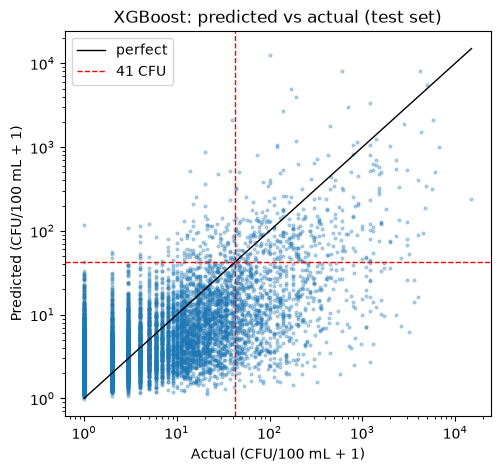

In [37]:
pred = np.expm1(models[best].predict(X_test))
actual = np.expm1(y_test)

plt.figure(figsize=(5.5, 5))
plt.scatter(actual + 1, pred + 1, s=4, alpha=0.3)
lims = [1, max(actual.max(), pred.max()) + 1]
plt.plot(lims, lims, 'k-', lw=1, label='perfect')
plt.axvline(THRESHOLD + 1, color='red', ls='--', lw=1); plt.axhline(THRESHOLD + 1, color='red', ls='--', lw=1, label='41 CFU')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Actual (CFU/100 mL + 1)'); plt.ylabel('Predicted (CFU/100 mL + 1)')
plt.title(f'{best}: predicted vs actual (test set)'); plt.legend(); plt.show()

### 10.4 Likely range and range-based warnings
**What it does:** Two extra XGBoost models predict a **low** (10th percentile) and **high** (90th percentile) estimate. Checks:
- how often the real count falls inside the range (target ~80%)
- a cautious warning rule: **warn if the high estimate ≥ 41**, compared with the best model's tuned cut-off (fewer missed poor days, more false alarms)

**Output:** Range coverage, median range, and a small table comparing the two warning rules.

In [38]:
range_models = {q: make_xgb(objective='reg:quantileerror', quantile_alpha=q).fit(X_trval, y_trval) for q in RANGE}
low = np.expm1(range_models[RANGE[0]].predict(X_test)).clip(min=0)
high = np.expm1(range_models[RANGE[1]].predict(X_test)).clip(min=0)
inside = (actual >= low) & (actual <= high)
print(f'Real count inside the predicted range: {inside.mean():.1%} (target {RANGE[1] - RANGE[0]:.0%})')
print(f'Median range: {np.median(low):.0f} to {np.median(high):.0f} CFU/100 mL')

true_poor = actual >= THRESHOLD
rules = {f'{best}: predicted ≥ {CUTOFFS[best]:.0f}': pred >= CUTOFFS[best],
         f'High estimate ≥ {THRESHOLD}': high >= THRESHOLD}
pd.DataFrame({name: {'recall (poor)': recall_score(true_poor, w), 'precision (poor)': precision_score(true_poor, w),
                     'F1 (poor)': f1_score(true_poor, w), 'missed poor days': int((true_poor & ~w).sum()),
                     'false alarms': int((~true_poor & w).sum())}
              for name, w in rules.items()}).T.round(3)

Real count inside the predicted range: 85.7% (target 80%)
Median range: 0 to 18 CFU/100 mL


,recall (poor),precision (poor),F1 (poor),missed poor days,false alarms
XGBoost: predicted ≥ 16,0.517,0.515,0.516,559.0,563.0
High estimate ≥ 41,0.718,0.331,0.453,326.0,1683.0


### 10.5 Example output: what a user would see
**What it does:** The most recent test predictions for the focus site: predicted count, likely range, risk call, and what the lab actually found.

**Output:** A table of the 10 most recent focus-site samples.

In [39]:
out = test[['site', 'date']].assign(
    predicted=pred.round(0), likely_low=low.round(0), likely_high=high.round(0),
    risk=np.where(pred >= CUTOFFS[best], 'POOR', 'safe'),
    actual=actual.round(0), actual_poor=np.where(actual >= THRESHOLD, 'POOR', 'safe'))
out[out['site'] == FOCUS_SITE].tail(10).reset_index(drop=True)

,site,date,predicted,likely_low,likely_high,risk,actual,actual_poor
0,Narrabeen Lagoon (Birdwood Park),2026-07-30,8.0,0.0,34.0,safe,0.0,safe
1,Narrabeen Lagoon (Birdwood Park),2026-08-05,5.0,0.0,16.0,safe,0.0,safe
2,Narrabeen Lagoon (Birdwood Park),2026-08-11,5.0,0.0,24.0,safe,6.0,safe
3,Narrabeen Lagoon (Birdwood Park),2026-08-17,71.0,6.0,273.0,POOR,54.0,POOR
4,Narrabeen Lagoon (Birdwood Park),2026-08-21,14.0,1.0,55.0,safe,41.0,POOR
5,Narrabeen Lagoon (Birdwood Park),2026-08-27,18.0,2.0,62.0,POOR,1.0,safe
6,Narrabeen Lagoon (Birdwood Park),2026-09-02,4.0,0.0,15.0,safe,5.0,safe
7,Narrabeen Lagoon (Birdwood Park),2026-09-08,8.0,0.0,38.0,safe,7.0,safe
8,Narrabeen Lagoon (Birdwood Park),2026-09-14,6.0,0.0,34.0,safe,0.0,safe
9,Narrabeen Lagoon (Birdwood Park),2026-09-21,3.0,0.0,11.0,safe,0.0,safe


### 10.6 Results per site
**What it does:** Best model's test results by site, at its tuned cut-off.

**Output:** A table per site sorted by number of poor days.

In [40]:
site_rows = []
for site, idx in test.groupby('site').groups.items():
    row = {'site': site, 'samples': len(idx), 'poor days': int(test.loc[idx, 'poor'].sum())}
    row.update(score(y_test.loc[idx], models[best].predict(X_test.loc[idx]), CUTOFFS[best]))
    site_rows.append(row)
print('Model:', best)
(pd.DataFrame(site_rows).set_index('site').drop(columns=['R² (log)'])
   .sort_values('poor days', ascending=False).round(3))

Model: XGBoost


,samples,poor days,MAE (log),typical error ×,recall (poor),precision (poor),F1 (poor)
site,,,,,,,
Bilarong Reserve,330,133,1.260,2.662,0.564,0.581,0.573
Narrabeen Lagoon (Birdwood Park),329,103,1.085,2.388,0.738,0.539,0.623
Bayview Baths,212,71,1.322,2.899,0.394,0.538,0.455
Shelly Beach (Manly),334,70,1.052,2.256,0.357,0.568,0.439
Queenscliff Beach,334,59,0.973,2.208,0.644,0.655,0.650
Davidson Reserve,217,53,1.026,2.454,0.906,0.658,0.762
South Steyne Beach,328,47,0.920,2.083,0.447,0.404,0.424
Gurney Crescent Baths,217,44,1.147,2.797,0.750,0.623,0.680
Freshwater Beach,335,36,0.967,2.226,0.278,0.323,0.299


# Part B: unseen sites (grouped cross-validation by site)
Part A tested future years at sites the model already knew. Here the model is tested on sites it has **never seen**.

**How it works:**
1. The 42 sites are split into **8 groups** of 5–6 sites, balanced by site type (from `site_types.csv`), so each group gets a mix and the rare types (lagoon, tidal pool, harbour beach) are spread out.
2. Each round: **6 groups train** the model, **1 group (validation)** tunes the poor/safe cut-off, **1 group (test)** is predicted by a model that never saw those sites. After tuning, the model is retrained on train + validation (~37 sites) before predicting the test group.
3. Rotate 8 times so every group is the test group once (and every site is tested exactly once).
4. Repeat the whole rotation **3 times** with different random groupings, to check results don't depend on which sites happen to land together.

**Fairness rules:** blank-filling medians and the cut-off come from training/validation sites only, every round. No input identifies a specific site (no `site_rate`). Previous-sample inputs are allowed (scenario: held-out sites are monitored, just not in training).

### 11.1 Site types used for balancing
**What it does:** Reads each site's type from the site-type columns added in 6.2 (falls back to 'unknown' if `site_types.csv` is missing).

**Output:** Number of sites per type.

In [41]:
type_cols = [c for c in df if c.startswith('type_')]
if type_cols:
    SITE_TYPE = df.groupby('site')[type_cols].first().idxmax(axis=1).str.replace('type_', '', regex=False)
else:
    SITE_TYPE = pd.Series('unknown', index=sorted(df['site'].unique()))
SITE_TYPE.value_counts().rename('sites').to_frame()

,sites
ocean beach,20
estuarine beach,9
netted baths / enclosure,6
harbour beach,3
lagoon,2
tidal pool,2


### 11.2 Make balanced site groups
**What it does:** `make_site_groups(seed)` shuffles sites within each type, then deals them out to the 8 groups like cards, smallest types first, so every type is spread across as many groups as possible. Different `seed` = different random grouping (used for the repeats).

**Output:** The groups for the first repeat: sites, types and poor rate in each group.

In [42]:
def make_site_groups(seed):
    rng = np.random.default_rng(seed)
    order = []
    for t in SITE_TYPE.value_counts(ascending=True).index:          # smallest types first
        order += list(rng.permutation(SITE_TYPE.index[SITE_TYPE == t]))
    labels = rng.permutation(N_GROUPS)
    return pd.Series({site: int(labels[i % N_GROUPS]) for i, site in enumerate(order)})

groups0 = make_site_groups(RANDOM_STATE)
site_poor = df.groupby('site')['poor'].mean()
pd.DataFrame({
    'sites': groups0.groupby(groups0).apply(lambda s: ', '.join(sorted(s.index))),
    'n sites': groups0.value_counts().sort_index(),
    'types': groups0.groupby(groups0).apply(lambda s: ', '.join(sorted(SITE_TYPE[s.index].unique()))),
    'poor rate': df.assign(g=df['site'].map(groups0)).groupby('g')['poor'].mean().round(3),
}).rename_axis('group')

,sites,n sites,types,poor rate
group,,,,
0,"Clareville Beach, Clontarf Pool, Dee Why Beach...",5,"estuarine beach, netted baths / enclosure, oce...",0.114
1,"Long Reef Beach, Manly Cove, Mona Vale Beach, ...",5,"estuarine beach, harbour beach, ocean beach",0.062
2,"Elvina Bay, Narrabeen Lagoon (Birdwood Park), ...",6,"estuarine beach, lagoon, netted baths / enclos...",0.118
3,"Avalon Beach, Bilgola Beach, Forty Baskets Poo...",5,"estuarine beach, netted baths / enclosure, oce...",0.068
4,"Fairlight Beach, Great Mackerel Beach, Newport...",5,"estuarine beach, harbour beach, netted baths /...",0.086
5,"Barrenjoey Beach, Bilarong Reserve, Collaroy B...",6,"estuarine beach, lagoon, netted baths / enclos...",0.108
6,"Little Manly Cove, Palm Beach, South Curl Curl...",5,"estuarine beach, harbour beach, ocean beach",0.053
7,"Bayview Baths, Bungan Beach, Davidson Reserve,...",5,"estuarine beach, netted baths / enclosure, oce...",0.117


### 11.3 The grouped cross-validation function
**What it does:** `run_grouped_cv()` does the whole procedure for a given feature list and set of models. For every repeat and every round:
1. Picks the test group (k) and validation group (k + 1); the other 6 groups train.
2. Fills blanks with the training medians, fits the model, scans cut-offs on the validation group and keeps the best F1.
3. Refits on train + validation and predicts the test group.
4. Scores the round, and also scores the two baselines (previous sample, training median; cut-off 41).

`future_only=True` gives the stricter check in Section 12: train/validation use years before `TEST_START`, the test group uses years from `TEST_START` onwards.

**Output:** Nothing (defines the function).

In [43]:
def tune_cutoff(y_true_log, pred_log):
    true_poor = np.expm1(y_true_log) >= THRESHOLD
    pred_cfu = np.expm1(pred_log)
    f1s = [f1_score(true_poor, pred_cfu >= c, zero_division=0) for c in CUT_CANDS]
    return float(CUT_CANDS[int(np.argmax(f1s))])

def run_grouped_cv(feats, model_names, repeats=N_REPEATS, future_only=False, baselines_too=True):
    rows, preds = [], []
    for rep in range(repeats):
        g = df['site'].map(make_site_groups(RANDOM_STATE + rep))
        for k in range(N_GROUPS):
            test_g, val_g = k, (k + 1) % N_GROUPS
            tr = df[(g != test_g) & (g != val_g)]
            va = df[g == val_g]
            te = df[g == test_g]
            if future_only:
                tr, va, te = tr[tr['date'] < TEST_START], va[va['date'] < TEST_START], te[te['date'] >= TEST_START]
            trva = pd.concat([tr, va])
            med_tr, med_trva = tr[feats].median(), trva[feats].median()
            info = {'repeat': rep, 'round': k, 'test sites': te['site'].nunique(), 'test rows': len(te)}

            for name in model_names:
                m = clone(models[name]).fit(tr[feats].fillna(med_tr), tr[TARGET])
                cutoff = tune_cutoff(va[TARGET], m.predict(va[feats].fillna(med_tr)))
                m = clone(models[name]).fit(trva[feats].fillna(med_trva), trva[TARGET])
                p = m.predict(te[feats].fillna(med_trva))
                rows.append({**info, 'model': name, 'cut-off': cutoff, **score(te[TARGET], p, cutoff)})
                preds.append(pd.DataFrame({'repeat': rep, 'round': k, 'model': name, 'site': te['site'].values,
                                           'date': te['date'].values, 'y': te[TARGET].values, 'pred': p,
                                           'cutoff': cutoff}))
            if baselines_too:
                for name, p in [('Baseline: previous sample', te['prev_entero_log'].values),
                                ('Baseline: training median', np.full(len(te), trva[TARGET].median()))]:
                    rows.append({**info, 'model': name, 'cut-off': THRESHOLD, **score(te[TARGET], p)})
    return pd.DataFrame(rows), pd.concat(preds, ignore_index=True)

METRICS = ['MAE (log)', 'typical error ×', 'R² (log)', 'recall (poor)', 'precision (poor)', 'F1 (poor)']

def summarise(rounds):
    """Mean ± spread (std) of each metric across all rounds and repeats."""
    agg = rounds.groupby('model', sort=False)[METRICS].agg(['mean', 'std'])
    return pd.DataFrame({m: agg[(m, 'mean')].map('{:.3f}'.format) + ' ± ' + agg[(m, 'std')].map('{:.3f}'.format)
                         for m in METRICS})

### 11.4 Run it
**What it does:** Runs the grouped cross-validation for `CV_MODELS` with all features. 8 rounds × 3 repeats.

**Output:** A progress note, then a table per model: mean ± spread across all 24 rounds. A small spread means the result is stable whichever sites are held out.

In [44]:
cv_rounds, cv_preds = run_grouped_cv(FEATURES, CV_MODELS)
print(f'{cv_rounds["round"].nunique()} rounds × {cv_rounds["repeat"].nunique()} repeats done')
summarise(cv_rounds)

8 rounds × 3 repeats done


,MAE (log),typical error ×,R² (log),recall (poor),precision (poor),F1 (poor)
model,,,,,,
XGBoost,0.954 ± 0.045,2.190 ± 0.096,0.386 ± 0.069,0.502 ± 0.087,0.491 ± 0.092,0.486 ± 0.056
Ridge,1.010 ± 0.066,2.308 ± 0.170,0.298 ± 0.060,0.460 ± 0.130,0.441 ± 0.099,0.427 ± 0.049
Baseline: previous sample,1.378 ± 0.111,2.951 ± 0.206,-0.531 ± 0.108,0.171 ± 0.048,0.170 ± 0.048,0.171 ± 0.048
Baseline: training median,1.221 ± 0.081,3.000 ± 0.000,-0.049 ± 0.039,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000


### 11.5 Results per site (unseen-site performance)
**What it does:** For the Part A best model, scores every site from the round where it was held out, averaged over the 3 repeats.

**Output:** A table per site: poor days, typical error, recall, precision, F1, sorted by poor days. Sites near the bottom with few poor days have unstable recall/F1.

In [45]:
cv_model = best if best in CV_MODELS else CV_MODELS[0]
cp = cv_preds[cv_preds['model'] == cv_model]

def per_group(frame, key):
    out = []
    for (grp, rep), s in frame.groupby([key, 'repeat']):
        out.append({key: grp, 'repeat': rep, 'samples': len(s),
                    'poor days': int((np.expm1(s['y']) >= THRESHOLD).sum()),
                    **score(s['y'], s['pred'], s['cutoff'].iloc[0] if s['cutoff'].nunique() == 1 else s['cutoff'].median())})
    return pd.DataFrame(out).drop(columns='repeat').groupby(key).mean()

print('Model:', cv_model)
site_res = per_group(cp, 'site').join(SITE_TYPE.rename('site type'))
site_res.drop(columns=['R² (log)']).sort_values('poor days', ascending=False).round(3)

Model: XGBoost


,samples,poor days,MAE (log),typical error ×,recall (poor),precision (poor),F1 (poor),site type
site,,,,,,,,
Narrabeen Lagoon (Birdwood Park),1229.0,353.0,1.075,2.428,0.686,0.518,0.580,lagoon
Davidson Reserve,1217.0,299.0,1.150,2.497,0.618,0.924,0.739,estuarine beach
Bayview Baths,1208.0,274.0,1.213,2.645,0.491,0.634,0.553,netted baths / enclosure
Bilarong Reserve,721.0,234.0,1.205,2.703,0.638,0.547,0.554,lagoon
Queenscliff Beach,1570.0,227.0,1.004,2.309,0.537,0.728,0.616,ocean beach
Shelly Beach (Manly),1570.0,205.0,1.146,2.480,0.260,0.513,0.343,ocean beach
Gurney Crescent Baths,1218.0,201.0,1.166,2.830,0.793,0.544,0.640,netted baths / enclosure
South Steyne Beach,1565.0,183.0,0.952,2.232,0.519,0.395,0.446,ocean beach
Clontarf Pool,1218.0,148.0,0.960,2.180,0.707,0.495,0.580,tidal pool


### 11.6 Results per site type
**What it does:** Same as 11.5 but pooled by site type: which kinds of site does the model generalise to well?

**Output:** A table per site type. Types with only 2–3 sites (lagoon, tidal pool, harbour beach) are the least certain.

In [46]:
type_res = per_group(cp.assign(site_type=cp['site'].map(SITE_TYPE)), 'site_type')
type_res.insert(0, 'sites', SITE_TYPE.value_counts())
type_res.drop(columns=['R² (log)']).sort_values('poor days', ascending=False).round(3)

,sites,samples,poor days,MAE (log),typical error ×,recall (poor),precision (poor),F1 (poor)
site_type,,,,,,,,
ocean beach,20,31440.0,2029.0,0.896,2.081,0.427,0.403,0.414
estuarine beach,9,10226.0,930.0,1.017,2.298,0.497,0.543,0.517
netted baths / enclosure,6,5432.0,887.0,1.120,2.588,0.619,0.584,0.600
lagoon,2,1950.0,587.0,1.123,2.513,0.656,0.526,0.576
harbour beach,3,3652.0,359.0,0.943,2.187,0.509,0.506,0.507
tidal pool,2,2435.0,268.0,0.964,2.209,0.690,0.480,0.564


## 12. Stricter check: unseen sites **and** future years
Same grouped rotation, but the model only learns from years before `TEST_START` and is tested on the held-out sites from `TEST_START` onwards. This is the hardest and most realistic test: a new site, in the future. It also uses the same test years as Part A, so it's the fairest comparison for the generalisation gap.

### 12.1 Run the stricter version
**What it does:** Runs `run_grouped_cv(..., future_only=True)` for the Part A best model and the baselines.

**Output:** Mean ± spread across all rounds.

In [47]:
strict_rounds, strict_preds = run_grouped_cv(FEATURES, [cv_model], future_only=True)
summarise(strict_rounds)

,MAE (log),typical error ×,R² (log),recall (poor),precision (poor),F1 (poor)
model,,,,,,
XGBoost,1.002 ± 0.071,2.277 ± 0.142,0.343 ± 0.084,0.482 ± 0.103,0.478 ± 0.107,0.467 ± 0.069
Baseline: previous sample,1.359 ± 0.129,2.779 ± 0.385,-0.439 ± 0.162,0.180 ± 0.087,0.180 ± 0.087,0.180 ± 0.087
Baseline: training median,1.267 ± 0.126,3.000 ± 0.000,-0.076 ± 0.061,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000


## 13. Do latitude/longitude help?
Coordinates can describe geography (north vs south, ocean vs harbour), but tree models can also use them to memorise individual sites, which doesn't transfer. This reruns the grouped CV with and without them.

### 13.1 With vs without coordinates
**What it does:** Runs the grouped CV for the Part A best model with and without `Latitude`/`Longitude` (same groupings, so the comparison is fair).

**Output:** Mean ± spread for both versions. If 'without' is as good or better, the coordinates aren't adding transferable information.

In [48]:
feats_with = FEATURES if 'Latitude' in FEATURES else FEATURES + ['Latitude', 'Longitude']
feats_without = [f for f in feats_with if f not in ('Latitude', 'Longitude')]

loc_runs = {}
for label, feats in [('with lat/lon', feats_with), ('without lat/lon', feats_without)]:
    r, _ = run_grouped_cv(feats, [cv_model], baselines_too=False)
    loc_runs[label] = r.assign(model=f'{cv_model} ({label})')
summarise(pd.concat(loc_runs.values()))

,MAE (log),typical error ×,R² (log),recall (poor),precision (poor),F1 (poor)
model,,,,,,
XGBoost (with lat/lon),0.954 ± 0.045,2.190 ± 0.096,0.386 ± 0.069,0.502 ± 0.087,0.491 ± 0.092,0.486 ± 0.056
XGBoost (without lat/lon),0.991 ± 0.054,2.253 ± 0.058,0.333 ± 0.109,0.488 ± 0.121,0.473 ± 0.100,0.461 ± 0.055


## 14. Generalisation gap

### 14.1 Known sites vs unseen sites
**What it does:** Puts the three tests side by side for the Part A best model:
- **Known sites, future years** (Part A, date split)
- **Unseen sites, all years** (Part B)
- **Unseen sites, future years** (Section 12, the strictest)

The drop from the first row to the others is the **generalisation gap**: how much worse the model is at a site it has never seen.

**Output:** A table of mean scores for the three tests.

In [49]:
gap = pd.DataFrame({
    'Known sites, future years (Part A)': results.loc[best, METRICS].astype(float),
    'Unseen sites, all years (Part B)': cv_rounds[cv_rounds['model'] == cv_model][METRICS].mean(),
    'Unseen sites, future years (Section 12)': strict_rounds[strict_rounds['model'] == cv_model][METRICS].mean(),
}).T.round(3)
print('Model:', cv_model)
gap

Model: XGBoost


,MAE (log),typical error ×,R² (log),recall (poor),precision (poor),F1 (poor)
"Known sites, future years (Part A)",0.928,2.135,0.461,0.517,0.515,0.516
"Unseen sites, all years (Part B)",0.954,2.190,0.386,0.502,0.491,0.486
"Unseen sites, future years (Section 12)",1.002,2.277,0.343,0.482,0.478,0.467


## 15. Next steps
**Part 1 (accuracy):**
- [ ] Use feature importance (9.4) to drop inputs that add nothing
- [ ] Hyperparameter tuning inside the grouped folds (tune on the validation group)

**Part 2 (generalisation):**
- [x] Grouped cross-validation by site (Part B), stricter site + time check (12), coordinates test (13), gap summary (14)
- [ ] Explain the gap per site type in the report (lagoons have only 2 sites)

**Part 3 (how long bacteria last):**
- [ ] Decay model: count(t) = count(0) × e^(−kt), k estimated per site type from dry-weather sample pairs
- [ ] Survival analysis (Kaplan–Meier / Cox) as an independent check

## 16. SHAP: explanations on held-out beaches

This section explains **XGBoost regression predictions** from grouped cross-validation. It refits XGBoost for each Part B split and uses the same site grouping, train/validation/test roles, and train-plus-validation median imputation as `run_grouped_cv()`. SHAP values are calculated only for the held-out test sites.

The summary reports mean absolute SHAP contribution across held-out predictions and the spread between folds. The beeswarm plot shows whether feature values push predicted `log_entero` up or down. These explain numeric regression predictions, not the tuned safe/poor threshold or F1 score.

**SHAP must already be installed in the active notebook kernel. This section does not install packages.** It refits one XGBoost model per fold, so it may take a few minutes.

In [50]:
import shap

SHAP_MODEL_NAME = 'XGBoost'
SHAP_PLOT_ROWS_PER_FOLD = 100
if SHAP_MODEL_NAME not in models:
    raise KeyError(f'{SHAP_MODEL_NAME!r} is not defined in models.')

shap_abs_sum = np.zeros(len(FEATURES), dtype=float)
shap_test_rows = 0
shap_fold_rows = []
shap_plot_values = []
shap_plot_features = []

for rep in range(N_REPEATS):
    site_groups = df['site'].map(make_site_groups(RANDOM_STATE + rep))
    for test_group in range(N_GROUPS):
        validation_group = (test_group + 1) % N_GROUPS
        train = df[(site_groups != test_group) & (site_groups != validation_group)]
        validation = df[site_groups == validation_group]
        test = df[site_groups == test_group]
        train_validation = pd.concat([train, validation])

        # Match the held-out test fit in run_grouped_cv().
        train_validation_medians = train_validation[FEATURES].median()
        x_train_validation = train_validation[FEATURES].fillna(train_validation_medians)
        x_test = test[FEATURES].fillna(train_validation_medians)
        fitted_xgb = clone(models[SHAP_MODEL_NAME])
        fitted_xgb.fit(x_train_validation, train_validation[TARGET])

        fold_explanation = shap.TreeExplainer(fitted_xgb)(x_test)
        fold_values = np.asarray(fold_explanation.values)
        if fold_values.shape != (len(test), len(FEATURES)):
            raise ValueError(
                f'Unexpected SHAP shape {fold_values.shape}; expected '
                f'({len(test)}, {len(FEATURES)}).'
            )

        # Confirm SHAP contributions reconstruct the model output on log_entero.
        base_values = np.asarray(fold_explanation.base_values).reshape(-1)
        if base_values.size == 1:
            base_values = np.full(len(test), base_values.item())
        prediction_error = np.max(np.abs(
            fold_values.sum(axis=1) + base_values - fitted_xgb.predict(x_test)
        ))
        if prediction_error > 1e-4:
            raise AssertionError(
                f'SHAP additivity check failed in repeat {rep + 1}, '
                f'fold {test_group + 1}: max error={prediction_error:.6g}.'
            )

        abs_values = np.abs(fold_values)
        shap_abs_sum += abs_values.sum(axis=0)
        shap_test_rows += len(test)
        shap_fold_rows.extend(
            {'repeat': rep + 1, 'fold': test_group + 1, 'feature': feature,
             'mean_abs_shap': abs_values[:, feature_index].mean()}
            for feature_index, feature in enumerate(FEATURES)
        )

        sample_count = min(SHAP_PLOT_ROWS_PER_FOLD, len(test))
        sample_indices = np.random.default_rng(
            RANDOM_STATE + rep * N_GROUPS + test_group
        ).choice(len(test), size=sample_count, replace=False)
        shap_plot_values.append(fold_values[sample_indices])
        shap_plot_features.append(x_test.iloc[sample_indices])

if shap_test_rows == 0:
    raise ValueError('No held-out rows were available for SHAP analysis.')

fold_shap = pd.DataFrame(shap_fold_rows)
fold_summary = fold_shap.groupby('feature')['mean_abs_shap'].agg(
    fold_mean='mean', fold_sd='std'
)
shap_summary = pd.DataFrame({
    'mean_abs_shap': shap_abs_sum / shap_test_rows
}).join(fold_summary).sort_values('mean_abs_shap', ascending=False)
display(shap_summary.round(4))

top_features = shap_summary.head(20).sort_values('mean_abs_shap')
top_features['mean_abs_shap'].plot(kind='barh', figsize=(8, 6))
plt.xlabel('Mean absolute SHAP value on log_entero scale')
plt.title('XGBoost: held-out beach feature contributions')
plt.tight_layout()
plt.show()

plot_explanation = shap.Explanation(
    values=np.vstack(shap_plot_values),
    data=pd.concat(shap_plot_features, ignore_index=True).to_numpy(),
    feature_names=FEATURES,
)
shap.plots.beeswarm(plot_explanation, max_display=20)
print(f'Explained {shap_test_rows:,} held-out predictions across '
      f'{N_REPEATS * N_GROUPS} grouped-CV folds.')

ModuleNotFoundError: No module named 'shap'